# Neural Network Playground: Understanding Training, Overfitting, and Regularization

This beginner-friendly notebook uses a small `make_moons` dataset to show how neural networks learn. Each experiment prints real results, so the conclusions are based on this run rather than guesses.

## 1. Setup

We import TensorFlow/Keras for neural networks and Scikit-learn for data and metrics. Random seeds make the experiment as repeatable as possible.

**What we learn:** A fixed seed helps different runs produce similar results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

np.random.seed(42)
tf.random.set_seed(42)
plt.rcParams['figure.figsize'] = (7, 4)

## 2. Dataset and Train-Test Split

`make_moons` creates two curved classes, so a neural network can learn a visible non-linear pattern. We keep some data aside as test data; the model sees the training data, but the test data checks performance on unseen examples.

**Conclusion:** A test set is a simple check against memorization.

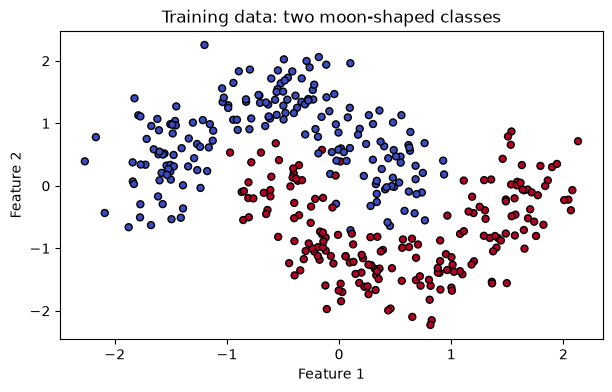

Train examples: 375, Test examples: 125


In [2]:
X, y = make_moons(n_samples=500, noise=0.20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', s=25)
plt.title('Training data: two moon-shaped classes')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2'); plt.show()
print(f'Train examples: {len(X_train)}, Test examples: {len(X_test)}')

## 3. Basic Neural Network

The input layer receives two features. Hidden layers contain neurons that learn patterns using ReLU; the output neuron uses sigmoid to produce a probability between 0 and 1. We train with binary cross-entropy loss and the Adam optimizer. An epoch is one pass through the training data.

**Weights** control the strength of connections, while **biases** shift neuron outputs.

**Conclusion:** A small Sequential model is enough to learn this simple boundary.

/Users/milinda/ghq/github.com/legion2004/breast-cancer-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Basic model - train accuracy: 0.984, test accuracy: 0.976


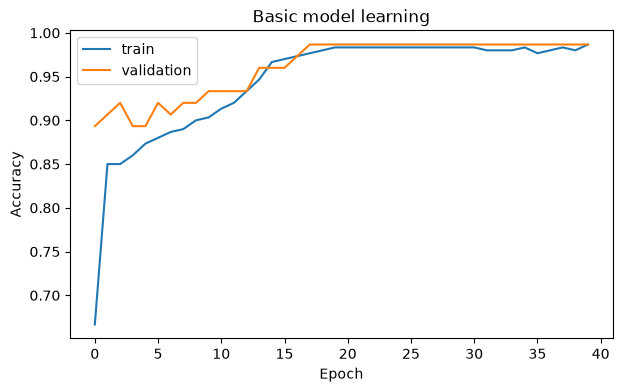

In [3]:
def build_model(hidden=(16, 8), learning_rate=0.01, regularizer=None, dropout_rate=0.0):
    model = Sequential([Dense(hidden[0], activation='relu', input_shape=(2,), kernel_regularizer=regularizer)])
    for units in hidden[1:]:
        model.add(Dense(units, activation='relu', kernel_regularizer=regularizer))
        if dropout_rate: model.add(Dropout(dropout_rate))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    return model

basic_model = build_model()
basic_history = basic_model.fit(X_train, y_train, validation_split=0.2, epochs=40, batch_size=32, verbose=0)
basic_train = basic_model.evaluate(X_train, y_train, verbose=0)
basic_test = basic_model.evaluate(X_test, y_test, verbose=0)
print(f'Basic model - train accuracy: {basic_train[1]:.3f}, test accuracy: {basic_test[1]:.3f}')
plt.plot(basic_history.history['accuracy'], label='train')
plt.plot(basic_history.history['val_accuracy'], label='validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Basic model learning'); plt.legend(); plt.show()

## 4. Forward Propagation and Backward Propagation

**Forward propagation** sends inputs through weighted connections and activations to make a prediction, then calculates loss. **Backward propagation** uses the loss gradient to update weights and biases so future predictions improve.

A Keras `fit` call performs both steps repeatedly. The tiny example below shows the idea with one sigmoid neuron.

In [4]:
x = np.array([1.0, 2.0]); target = 1.0
weights = np.array([0.20, -0.10]); bias = 0.05; learning_rate = 0.10
z = x @ weights + bias
prediction = 1 / (1 + np.exp(-z))
loss = -(target*np.log(prediction) + (1-target)*np.log(1-prediction))
gradient = (prediction - target) * x
new_weights = weights - learning_rate * gradient
print(f'Forward: z={z:.3f}, prediction={prediction:.3f}, loss={loss:.3f}')
print(f'Backward: gradient={gradient}, updated weights={new_weights}')
print('The real Keras model applies this same idea to many neurons and layers.')

Forward: z=0.050, prediction=0.512, loss=0.668
Backward: gradient=[-0.4875026  -0.97500521], updated weights=[ 0.24875026 -0.00249948]
The real Keras model applies this same idea to many neurons and layers.


## 5. Underfitting, Good Fit, and Overfitting

A very small model may be too weak (**underfitting**). A balanced model learns the useful pattern. A very large model trained for many epochs can memorize training details (**overfitting**).

We compare training and test accuracy and draw decision boundaries. The plots are practical evidence, not a proof that one model is always best.

,Model,Train accuracy,Test accuracy,Gap
0,Underfitting,0.848,0.824,0.024
1,Good fit,0.981,0.976,0.005
2,Overfitting candidate,0.992,0.968,0.024


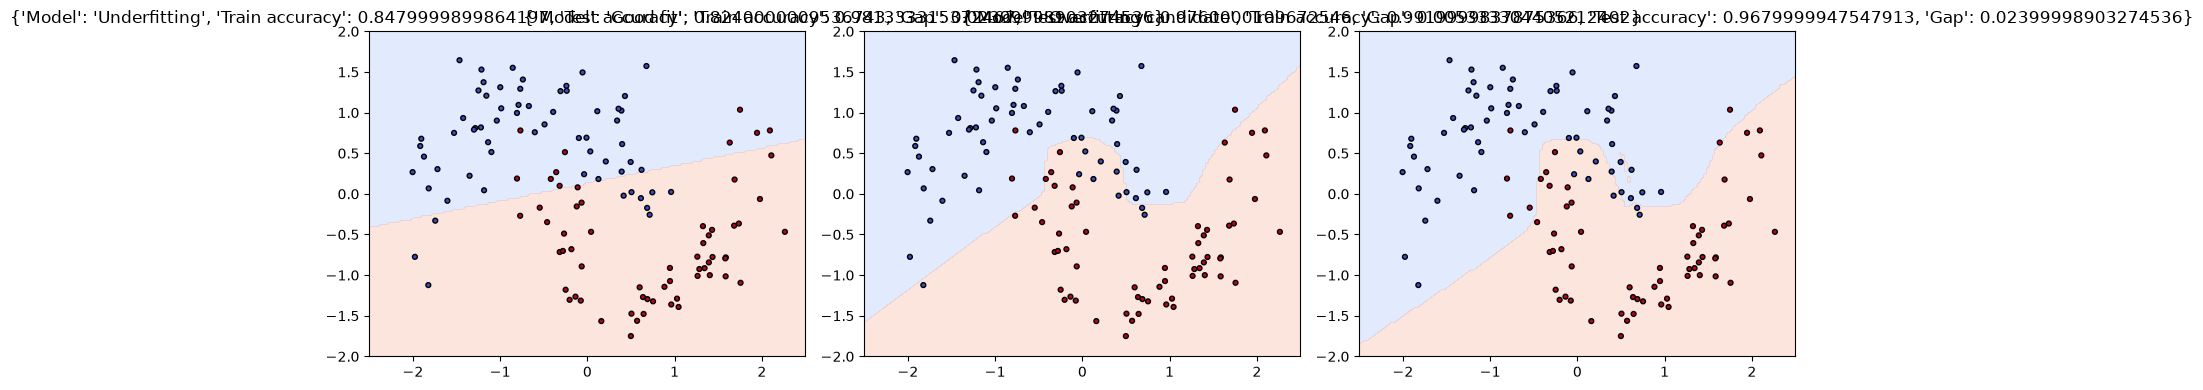

In [5]:
def train_and_score(name, hidden, epochs):
    model = build_model(hidden=hidden)
    history = model.fit(X_train, y_train, validation_split=0.2, epochs=epochs, batch_size=16, verbose=0)
    train_acc = model.evaluate(X_train, y_train, verbose=0)[1]
    test_acc = model.evaluate(X_test, y_test, verbose=0)[1]
    return {'Model': name, 'Train accuracy': train_acc, 'Test accuracy': test_acc, 'Gap': train_acc-test_acc}, model, history

experiments = [train_and_score('Underfitting', (2,), 25), train_and_score('Good fit', (16, 8), 60), train_and_score('Overfitting candidate', (64, 64, 32), 250)]
complexity_table = pd.DataFrame([item[0] for item in experiments])
display(complexity_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, item in zip(axes, experiments):
    model = item[1]
    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 150), np.linspace(-2, 2, 150))
    grid = scaler.transform(np.c_[xx.ravel(), yy.ravel()])
    zz = model.predict(grid, verbose=0).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0.5, alpha=0.25, cmap='coolwarm')
    ax.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap='coolwarm', edgecolor='k', s=12)
    ax.set_title(item[0])
plt.tight_layout(); plt.show()

## 6. Bias and Variance

High bias means the model is too simple and misses the underlying pattern. Low bias means it captures the pattern well. High variance means performance changes sharply between training and unseen data; low variance means it is more consistent.

Accuracy and the train-test gap are useful practical indicators, but they are not exact mathematical measurements of bias and variance.

**Viva sentence:** Underfitting usually suggests high bias; a large train-test gap often suggests high variance.

In [6]:
bias_variance = complexity_table.copy()
bias_variance['Interpretation'] = [
    'Likely high bias: simple model misses the curves',
    'Likely lower bias and lower variance: balanced results',
    'Possible high variance if train accuracy greatly exceeds test accuracy'
]
display(bias_variance.round(3))

,Model,Train accuracy,Test accuracy,Gap,Interpretation
0,Underfitting,0.848,0.824,0.024,Likely high bias: simple model misses the curves
1,Good fit,0.981,0.976,0.005,Likely lower bias and lower variance: balanced...
2,Overfitting candidate,0.992,0.968,0.024,Possible high variance if train accuracy great...


## 7. L1 and L2 Regularization

Regularization adds a penalty to the loss when weights become large. L1 uses the absolute value of weights and can push some weights close to zero. L2 uses squared weights and usually shrinks weights smoothly. Both can help reduce overfitting.

**Conclusion:** Compare the test accuracy and train-test gap rather than assuming a regularizer always wins.

In [7]:
regularized = []
for name, penalty in [('No regularization', None), ('L1', l1(0.01)), ('L2', l2(0.01))]:
    model = build_model(hidden=(32, 16), regularizer=penalty)
    model.fit(X_train, y_train, validation_split=0.2, epochs=80, batch_size=16, verbose=0)
    tr = model.evaluate(X_train, y_train, verbose=0)[1]; te = model.evaluate(X_test, y_test, verbose=0)[1]
    regularized.append({'Model': name, 'Train accuracy': tr, 'Test accuracy': te, 'Gap': tr-te})
display(pd.DataFrame(regularized).round(3))

/Users/milinda/ghq/github.com/legion2004/breast-cancer-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Model,Train accuracy,Test accuracy,Gap
0,No regularization,0.981,0.960,0.021
1,L1,0.861,0.824,0.037
2,L2,0.973,0.968,0.005


## 8. Dropout (sometimes mistakenly called Dropoff)

Dropout randomly disables a fraction of neurons during training. With `Dropout(0.3)`, about 30% of eligible neuron outputs are temporarily removed in each training step. This encourages the network not to depend too much on one path.

At test time, Keras automatically uses all neurons with the appropriate scaling.

In [8]:
dropout_results = []
for name, rate in [('No dropout', 0.0), ('Dropout 0.3', 0.3)]:
    model = build_model(hidden=(32, 16), dropout_rate=rate)
    history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, batch_size=16, verbose=0)
    tr = model.evaluate(X_train, y_train, verbose=0)[1]; te = model.evaluate(X_test, y_test, verbose=0)[1]
    dropout_results.append({'Model': name, 'Train accuracy': tr, 'Test accuracy': te, 'Gap': tr-te})
display(pd.DataFrame(dropout_results).round(3))

/Users/milinda/ghq/github.com/legion2004/breast-cancer-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Model,Train accuracy,Test accuracy,Gap
0,No dropout,0.984,0.968,0.016
1,Dropout 0.3,0.989,0.960,0.029


## 9. Early Stopping

Validation loss measures error on a validation subset that is not used for weight updates. `patience=5` allows five more epochs without improvement before stopping. `restore_best_weights=True` returns the model to the weights from its best validation-loss epoch.

**Conclusion:** Early stopping can limit unnecessary training and reduce overfitting.

/Users/milinda/ghq/github.com/legion2004/breast-cancer-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Stopped after 11 epochs; train=0.984, test=0.976


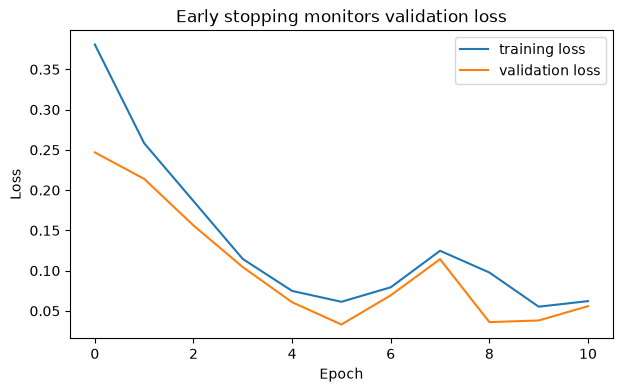

In [10]:
early_model = build_model(hidden=(64, 64, 32))
stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
early_history = early_model.fit(X_train, y_train, validation_split=0.2, epochs=300, batch_size=16, callbacks=[stop], verbose=0)
tr = early_model.evaluate(X_train, y_train, verbose=0)[1]
te = early_model.evaluate(X_test, y_test, verbose=0)[1]
epoch_count = len(early_history.history['loss'])
print(f'Stopped after {epoch_count} epochs; train={tr:.3f}, test={te:.3f}')
plt.plot(early_history.history['loss'], label='training loss')
plt.plot(early_history.history['val_loss'], label='validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Early stopping monitors validation loss'); plt.legend(); plt.show()

## 10. Hyperparameters

Hyperparameters are choices made before training, such as layer count, neuron count, learning rate, batch size, epoch limit, and dropout rate. Changing one can change speed, training accuracy, and generalization.

The following small experiment changes one setting at a time from a common baseline. Results can vary slightly because neural-network training is stochastic.

In [11]:
settings = [
    ('1 hidden layer', (16,), 0.01, 16, 50, 0.0),
    ('3 hidden layers', (32,16,8), 0.01, 16, 50, 0.0),
    ('Small learning rate', (16,8), 0.001, 16, 50, 0.0),
    ('Large batch', (16,8), 0.01, 64, 50, 0.0),
    ('More epochs', (16,8), 0.01, 16, 100, 0.0),
    ('More dropout', (16,8), 0.01, 16, 50, 0.3)]
hyper_rows = []
for name, hidden, rate, batch, epochs, drop in settings:
    model = build_model(hidden, rate, dropout_rate=drop)
    model.fit(X_train, y_train, validation_split=0.2, epochs=epochs, batch_size=batch, verbose=0)
    hyper_rows.append({'Change': name, 'Train accuracy': model.evaluate(X_train,y_train,verbose=0)[1], 'Test accuracy': model.evaluate(X_test,y_test,verbose=0)[1]})
display(pd.DataFrame(hyper_rows).round(3))

,Change,Train accuracy,Test accuracy
0,1 hidden layer,0.984,0.984
1,3 hidden layers,0.984,0.976
2,Small learning rate,0.931,0.904
3,Large batch,0.984,0.992
4,More epochs,0.989,0.968
5,More dropout,0.987,0.984


## 11. Final Comparison

This table collects the main model families in one place. The interpretation should be read together with the actual accuracy values, because the best choice depends on the experiment and the dataset.

**Overall conclusion:** A good model learns the pattern while keeping test performance close to training performance. Regularization, dropout, and early stopping are tools for controlling a model that is too flexible.

In [13]:
final_rows = []
def add_final(name, model):
    tr = model.evaluate(X_train, y_train, verbose=0)[1]
    te = model.evaluate(X_test, y_test, verbose=0)[1]
    final_rows.append({'Model': name, 'Train accuracy': tr, 'Test accuracy': te, 'Interpretation': 'higher test score is better; compare the gap'})
add_final('Basic model', basic_model)
for item in experiments:
    add_final(item[0]['Model'], item[1])
for name, penalty in [('L1 model', l1(0.01)), ('L2 model', l2(0.01))]:
    model = build_model((32,16), regularizer=penalty)
    model.fit(X_train, y_train, epochs=80, batch_size=16, verbose=0)
    add_final(name, model)
model = build_model((32,16), dropout_rate=0.3)
model.fit(X_train, y_train, epochs=100, batch_size=16, verbose=0)
add_final('Dropout model', model)
add_final('Early stopping model', early_model)
display(pd.DataFrame(final_rows).round(3))

/Users/milinda/ghq/github.com/legion2004/breast-cancer-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Model,Train accuracy,Test accuracy,Interpretation
0,Basic model,0.984,0.976,higher test score is better; compare the gap
1,Underfitting,0.848,0.824,higher test score is better; compare the gap
2,Good fit,0.981,0.976,higher test score is better; compare the gap
3,Overfitting candidate,0.992,0.968,higher test score is better; compare the gap
4,L1 model,0.861,0.832,higher test score is better; compare the gap
5,L2 model,0.971,0.968,higher test score is better; compare the gap
6,Dropout model,0.992,0.984,higher test score is better; compare the gap
7,Early stopping model,0.984,0.976,higher test score is better; compare the gap


## 12. Viva Preparation

1. **What is a neural network?** A set of connected layers that learns useful weights from examples.
2. **What is a neuron?** It calculates a weighted sum, adds a bias, and applies an activation function.
3. **Why use ReLU?** It is simple and helps hidden layers learn non-linear patterns.
4. **Why use sigmoid at the output?** It gives a probability for binary classification.
5. **What is forward propagation?** Passing inputs forward to calculate predictions and loss.
6. **What is backward propagation?** Sending loss gradients backward to update weights.
7. **What is an epoch?** One pass through the training data.
8. **What is underfitting?** The model is too simple and performs poorly even on training data.
9. **What is overfitting?** The model fits training details but performs worse on unseen data.
10. **What is high bias?** Error caused by a model that is too simple.
11. **What is high variance?** A model is sensitive to training data and has a large train-test performance gap.
12. **What does L1 do?** It adds an absolute-weight penalty and may make some weights nearly zero.
13. **What does L2 do?** It adds a squared-weight penalty and smoothly shrinks large weights.
14. **Why use dropout?** It temporarily removes neurons during training to reduce dependence on particular paths.
15. **Why use early stopping?** It stops when validation loss stops improving and restores the best weights.